<a href="https://colab.research.google.com/github/teja01721/APS-LAB/blob/main/RandomVariableAPS23_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [42]:
import numpy as np
np.random.seed(42)
p=0.30
sample_size=20
samples=np.random.binomial(n=1,p=p,size=sample_size)
print(samples)

[0 1 1 0 0 0 0 1 0 1 0 1 1 0 0 0 0 0 0 0]


In [43]:
#count clicks and non clicks

number_of_clicks = np.sum(samples == 1)
number_of_non_clicks = np.sum(samples == 0)
print("clicks",number_of_clicks)
print("non clicks",number_of_non_clicks)

clicks 6
non clicks 14


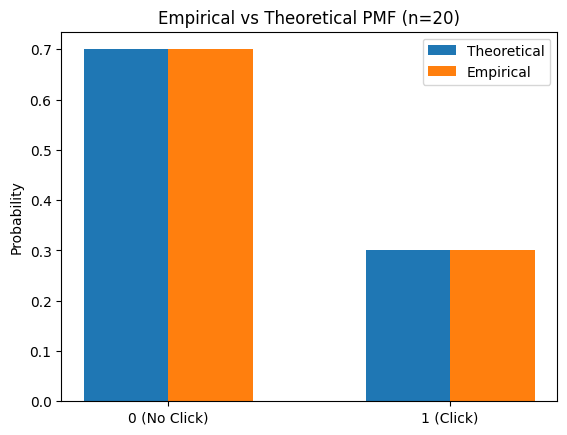

In [44]:
import matplotlib.pyplot as plt
x_vals = [0, 1]
theoretical_pmf = [0.70, 0.30]
empirical_pmf = [number_of_non_clicks / sample_size, number_of_clicks / sample_size]
plt.bar(
    [x - 0.15 for x in x_vals],
    theoretical_pmf,
    width=0.3,
    label="Theoretical",
    align="center",
)
plt.bar(
    [x + 0.15 for x in x_vals],
    empirical_pmf,
    width=0.3,
    label="Empirical",
    align="center",
)
plt.xticks(x_vals, ["0 (No Click)", "1 (Click)"])
plt.ylabel("Probability")
plt.title("Empirical vs Theoretical PMF (n=20)")
plt.legend()
plt.show()

In [47]:
sample_sizes = [10, 100, 1000, 10000]  #[cite: 1]

for N in sample_sizes:
    s = np.random.binomial(n=1, p=0.30, size=N)
    p0 = np.mean(s == 0)
    p1 = np.mean(s == 1)
    mean = np.mean(s)
    var = np.var(s)
    print(
        f"Size: {N:5d} | Empirical P(0): {p0:.4f} | Empirical P(1): {p1:.4f} | Mean: {mean:.4f} | Var: {var:.4f}"
    )

Size:    10 | Empirical P(0): 0.6000 | Empirical P(1): 0.4000 | Mean: 0.4000 | Var: 0.2400
Size:   100 | Empirical P(0): 0.7200 | Empirical P(1): 0.2800 | Mean: 0.2800 | Var: 0.2016
Size:  1000 | Empirical P(0): 0.6950 | Empirical P(1): 0.3050 | Mean: 0.3050 | Var: 0.2120
Size: 10000 | Empirical P(0): 0.7027 | Empirical P(1): 0.2973 | Mean: 0.2973 | Var: 0.2089


In [46]:
import numpy as np

np.random.seed(42)

# Simulate 20,000 independent one-hour periods
num_simulations = 20000  #[cite: 1]
n_transactions = 50  #[cite: 1]
p_flag = 0.04  #[cite: 1]

# Generate binomial outcomes for 20,000 hours
flagged_counts = np.random.binomial(
    n=n_transactions, p=p_flag, size=num_simulations
)  #[cite: 1]

# Calculations
capacity = 4  #[cite: 1]
over_capacity_hours = np.sum(flagged_counts > capacity)
prob_over_capacity = np.mean(flagged_counts > capacity)

print(f"Mean flagged transactions per hour: {np.mean(flagged_counts):.4f}")
print(f"Hours exceeding capacity (> 4): {over_capacity_hours} / {num_simulations}")
print(f"Probability of exceeding capacity: {prob_over_capacity:.4f}")

Mean flagged transactions per hour: 1.9987
Hours exceeding capacity (> 4): 968 / 20000
Probability of exceeding capacity: 0.0484


# Problem Set 2: ML Use Case: Number of Fraudulent Transactions Flagged **bold text**

In [54]:
import numpy as np
np.random.seed(42)
transactions=50
p_flag=0.04
n_simulation=20000
max_capacity=4
X = np.random.binomial(n=transactions, p=p_flag, size=n_simulation)
prob_exceed_capacity = np.mean(X > max_capacity)
unexamined_transactions = np.maximum(0, X - max_capacity)
total_unexamined = np.sum(unexamined_transactions)
avg_unexamined = np.mean(unexamined_transactions)



print(f"Simulated mean flagged transactions per hour: {np.mean(X):.4f}")
print(f"Theoretical mean: {transactions * p_flag}")
print(f"Probability that capacity is exceeded (X > 4): {prob_exceed_capacity:.4f}")
print(f"Total unexamined flagged transactions: {total_unexamined}")
print(f"Average unexamined flagged transactions per hour: {avg_unexamined:.4f}")

Simulated mean flagged transactions per hour: 1.9987
Theoretical mean: 2.0
Probability that capacity is exceeded (X > 4): 0.0484
Total unexamined flagged transactions: 1353
Average unexamined flagged transactions per hour: 0.0677


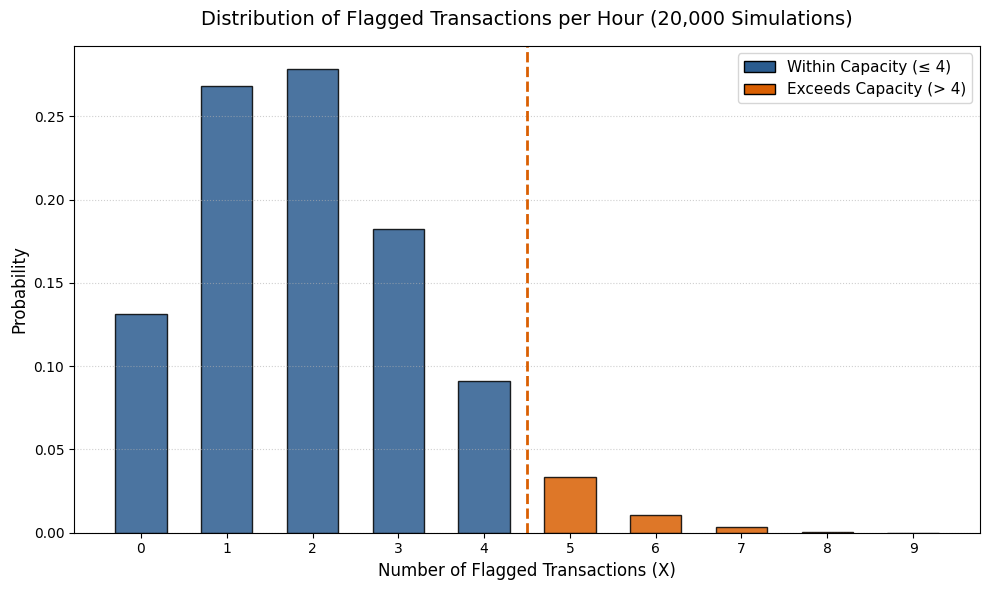

In [55]:
import matplotlib.pyplot as plt
import numpy as np

# Set random seed and parameters
np.random.seed(42)
transactions = 50
p_flag = 0.04
n_simulation = 20000
max_capacity = 4

# Run simulation
X = np.random.binomial(n=transactions, p=p_flag, size=n_simulation)

# Plot setup
plt.figure(figsize=(10, 6))

# Count frequencies for each possible outcome
values, counts = np.unique(X, return_counts=True)
probabilities = counts / n_simulation

# Color bars based on capacity limit (Within Capacity vs Exceeded Capacity)
colors = [
    "#2b5c8f" if val <= max_capacity else "#d95f02" for val in values
]

# Create bar plot
bars = plt.bar(
    values,
    probabilities,
    color=colors,
    edgecolor="black",
    alpha=0.85,
    width=0.6,
)

# Vertical dashed line for Max Capacity
plt.axvline(
    x=max_capacity + 0.5,
    color="#d95f02",
    linestyle="--",
    linewidth=2,
    label=f"Capacity Limit ({max_capacity})",
)

# Annotations and Labels
plt.title(
    "Distribution of Flagged Transactions per Hour (20,000 Simulations)",
    fontsize=14,
    pad=15,
)
plt.xlabel("Number of Flagged Transactions (X)", fontsize=12)
plt.ylabel("Probability", fontsize=12)
plt.xticks(np.arange(0, max(values) + 1, 1))
plt.grid(axis="y", linestyle=":", alpha=0.6)

# Add custom legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="#2b5c8f", edgecolor="black", label="Within Capacity (≤ 4)"),
    Patch(facecolor="#d95f02", edgecolor="black", label="Exceeds Capacity (> 4)"),
]
plt.legend(handles=legend_elements, loc="upper right", fontsize=11)

plt.tight_layout()
plt.show()